In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
os.makedirs("outputs", exist_ok=True) 
data = {
    "Study_Hours": [2, 3, 4, 5, 6, 7, 8, 9],
    "Attendance": [60, 65, 70, 75, 80, 85, 90, 95],
    "Previous_Marks": [45, 50, 55, 60, 65, 70, 80, 85],
    "Final_Marks": [40, 48, 55, 62, 68, 75, 85, 92]
}

df = pd.DataFrame(data) 
print("STUDENT PERFORMANCE TRACKER")
print("\nStudent Dataset:")
print(df) 

STUDENT PERFORMANCE TRACKER

Student Dataset:
   Study_Hours  Attendance  Previous_Marks  Final_Marks
0            2          60              45           40
1            3          65              50           48
2            4          70              55           55
3            5          75              60           62
4            6          80              65           68
5            7          85              70           75
6            8          90              80           85
7            9          95              85           92



Model Evaluation
Actual Marks: [48, 75]
Predicted Marks: [47.43 75.65]
Mean Absolute Error: 0.61

New Student Details:
   Study_Hours  Attendance  Previous_Marks
0            6          85              70
Expected Final Marks: 75.46


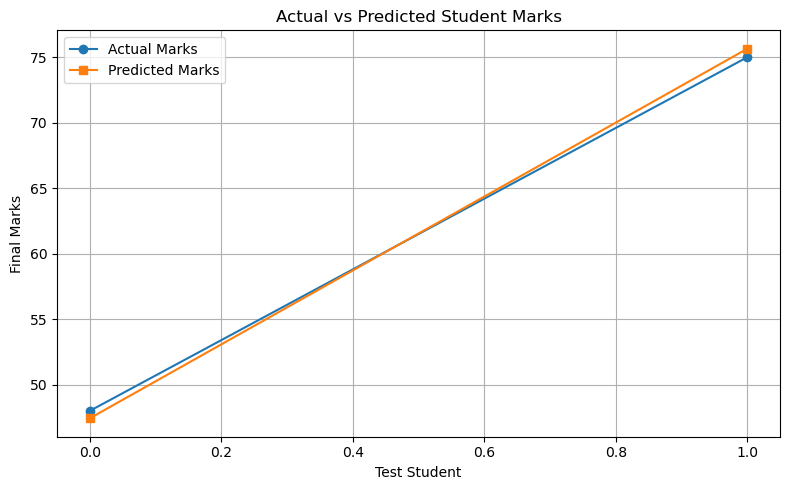

In [2]:
X = df[["Study_Hours", "Attendance", "Previous_Marks"]]
y = df["Final_Marks"] 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
) 
model = LinearRegression()
model.fit(X_train, y_train) 
predictions = model.predict(X_test) 
mae = mean_absolute_error(y_test, predictions)
print("\nModel Evaluation")
print("Actual Marks:", list(y_test))
print("Predicted Marks:", predictions.round(2))
print("Mean Absolute Error:", round(mae, 2)) 
new_student = pd.DataFrame([{
    "Study_Hours": 6,
    "Attendance": 85,
    "Previous_Marks": 70
}]) 
result = model.predict(new_student) 
print("\nNew Student Details:")
print(new_student) 
print("Expected Final Marks:", round(result[0], 2)) 
plt.figure(figsize=(8, 5))

plt.plot(
    range(len(y_test)),
    y_test.values,
    marker="o",
    label="Actual Marks"
)

plt.plot(
    range(len(predictions)),
    predictions,
    marker="s",
    label="Predicted Marks"
)

plt.title("Actual vs Predicted Student Marks")
plt.xlabel("Test Student")
plt.ylabel("Final Marks")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("outputs/actual_vs_predicted.png")
plt.show()
plt.close() 

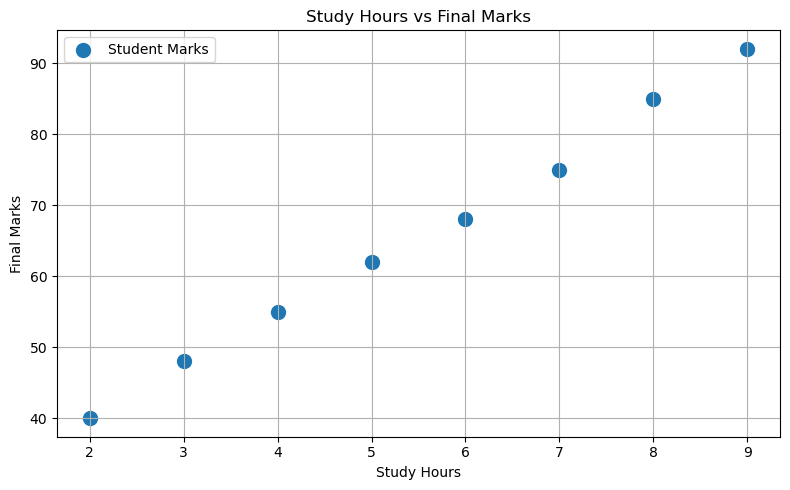

In [3]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Study_Hours"],
    df["Final_Marks"],
    s=100,
    label="Student Marks"
)

plt.title("Study Hours vs Final Marks")
plt.xlabel("Study Hours")
plt.ylabel("Final Marks")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("outputs/study_hours_vs_marks.png")
plt.show()
plt.close() 

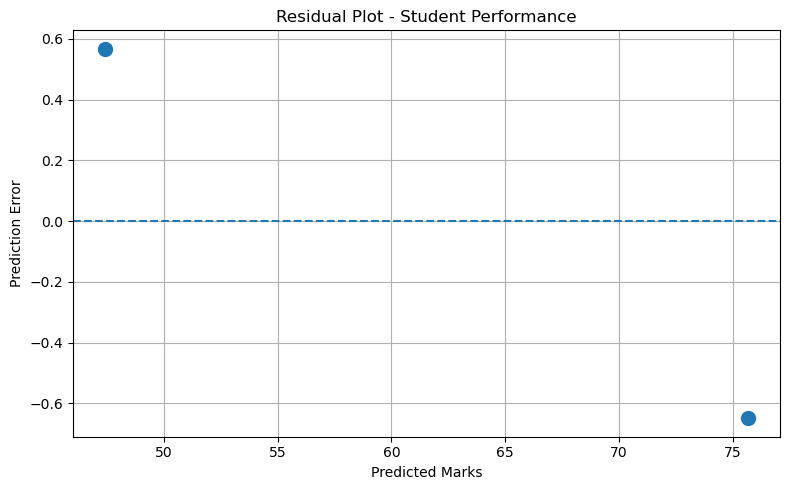


All Four Visualizations Saved Successfully!
Check the outputs folder.


In [4]:
residuals = y_test.values - predictions

plt.figure(figsize=(8, 5))

plt.scatter(
    predictions,
    residuals,
    s=100
)

plt.axhline(y=0, linestyle="--")

plt.title("Residual Plot - Student Performance")
plt.xlabel("Predicted Marks")
plt.ylabel("Prediction Error")
plt.grid(True)

plt.tight_layout()
plt.savefig("outputs/residual_plot.png")
plt.show()
plt.close() 
print("\nAll Four Visualizations Saved Successfully!")
print("Check the outputs folder.") 